# JupyerLab notebook reproducing R. Labarbe results

/!\ /!\ /!\  
Oxygen diffusion from cell environment not (yet) included in the model.  
Therefore, the oxygen level is reinitialized before each new pulse.  

## Module imports

In [1]:
# External modules (to "pip install")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson, cumulative_trapezoid

# Modules from Standard lib
from pathlib import Path

# RadioBio module
import radiopyo_wip.radiopyo as rpw
from radiopyo_wip.radiopyo.physics.beam import PulsedBeam, ConstantBeam

In [2]:
from Plot_template import RPlot, FigManager
RPlot.init_rcparams()
fig_man = FigManager()

In [22]:
rpw

<module 'radiopyo_wip.radiopyo' from 'C:\\Users\\rtonneau\\DEV\\PYTHON\\radiopyo_wip\\radiopyo\\__init__.py'>

## Simulation Run

In [3]:
uc = rpw.UnitCell.from_toml(rpw.LABARBE_CONFIG_FILE)

2023-09-22 10:04:17,224::radiopyo::INFO::Loading config from file: C:\Users\rtonneau\DEV\PYTHON\radiopyo\radiopyo\data\config_Labarbe.toml
2023-09-22 10:04:17,232::radiopyo::INFO::Resolving include: C:\Users\rtonneau\DEV\PYTHON\radiopyo\radiopyo\data\basic_water_radiolysis.toml
2023-09-22 10:04:17,434::radiopyo::INFO::Resolving include: C:\Users\rtonneau\DEV\PYTHON\radiopyo\radiopyo\data\reactions_biology.toml
2023-09-22 10:04:17,482::radiopyo::WARNING::Unable to compute mass of GSH. Setting it to default mass, i.e. 0
2023-09-22 10:04:17,729::radiopyo::INFO::File is loaded
2023-09-22 10:04:17,729::radiopyo::INFO::Beam configuration detected in config file
2023-09-22 10:04:17,730::radiopyo::INFO::BEAM:: Assigning 'default' name to beam definition constant -> {'dose_rate': 10000000.0, 'max_dose': 10, 'start_time': 0.0, 'LET': 0.201}
2023-09-22 10:04:17,731::radiopyo::INFO::CONFIG::Configuring Simulation Environment
2023-09-22 10:04:17,732::radiopyo::INFO::CONFIG::3 Acid/Base reactions ad

In [6]:
uc.beam_list.current

ConstantBeam(dose_rate=1, timer=Timer(period=inf, on_time=inf, start_time=0.0), max_dose=10, label='default', time_at_max_dose=10.0, dose_per_pulse=inf, peak_dose_rate=1.0)

In [4]:
dose_rate = [1, 10, 1e3, 1e5, 1e7]
sims = dict()

for idx, value in enumerate(dose_rate):
    print(f"Simulating conv: {value} Gy")
    uc.beam_list.current.update_beam_param(dose_rate=value)
    sim = uc.prepare_chunked_run([1e-9, 600], atol=1e-8, rtol=1e-4, use_jac=False)
    res = sim.run()
    sims[value] = res.to_pandas()





Simulating conv: 1 Gy
2023-09-22 10:04:48,531::radiopyo::INFO::Simulation divided in 2 chunks
2023-09-22 10:04:48,534::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-09-22 10:04:49,260::radiopyo::INFO::Simulation done!
Simulating conv: 10 Gy
2023-09-22 10:04:49,264::radiopyo::INFO::Simulation divided in 2 chunks
2023-09-22 10:04:49,266::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-09-22 10:04:50,415::radiopyo::INFO::Simulation done!
Simulating conv: 1000.0 Gy
2023-09-22 10:04:50,418::radiopyo::INFO::Simulation divided in 2 chunks
2023-09-22 10:04:50,421::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-09-22 10:04:50,856::radiopyo::INFO::Simulation done!
Simulating conv: 100000.0 Gy
2023-09-22 10:04:50,859::radiopyo::INFO::Simulation divided in 2 chunks
2023-09-22 10:04:50,861::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-09-22 10:04:51,378::radiopyo::INFO::Simulation done!
Simulating conv: 10000000.0 Gy
2023-09-22 10:04:51,381::radiopyo::INFO::Simulation divided in 2 chunks
2023-09-22 10:04:51,384::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-09-22 10:04:52,017::radiopyo::INFO::Simulation done!


In [21]:
dir(uc.env.species)

['__annotations__',
 '__class__',
 '__contains__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__iter__',
 '__le__',
 '__len__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__slotnames__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_add_species',
 '_convert_to_CstSpecies',
 'add_cst_species',
 'add_dyn_species',
 'cst_sp',
 'dyn_sp',
 'get',
 'get_or_create_cst_species',
 'get_or_create_dyn_species',
 'is_dyn_species',
 'iter_cst_species',
 'iter_dyn_species',
 'len_cst_species',
 'len_dyn_species',
 'next_index',
 'sort',
 'sorted',
 'sorted_iter_cst_species',
 'sorted_iter_dyn_species']

In [13]:
sims[1]

,OH_r,O_r_minus,H2O2,HO2_minus,HO2_r,O2_r_minus,O2,Fe_plus_plus_plus,H_r,RH_r,e_aq,R_r,ROO_r,ROH,RO,ROOH,H2,O2_minus_minus,O3_minus
1.000000e-09,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,50.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
1.001000e-09,2.816528e-13,3.545799e-18,6.986847e-14,1.394059e-18,2.608806e-21,3.284292e-19,50.000000,6.218293e-29,6.217765e-14,6.368855e-17,2.797384e-13,6.143084e-14,1.535779e-22,2.337015e-58,2.337015e-58,3.057460e-39,4.405903e-14,1.194524e-39,6.382431e-25
1.002000e-09,5.630060e-13,7.087826e-18,1.397369e-13,2.788118e-18,7.826070e-21,9.852438e-19,50.000000,1.865488e-28,1.243490e-13,1.910400e-16,5.594373e-13,1.231430e-13,4.614362e-22,2.356442e-57,2.356442e-57,1.227210e-38,8.811807e-14,8.360210e-39,1.914051e-24
2.690271e-09,4.765757e-10,5.999732e-15,1.180966e-10,2.356337e-15,5.773178e-15,7.268001e-13,50.000000,1.774475e-22,9.023629e-11,9.990162e-11,3.871374e-10,1.033552e-10,3.824941e-15,3.272346e-42,3.272346e-42,1.486554e-29,7.447177e-11,7.412237e-27,1.914051e-24
4.378541e-09,9.525884e-10,1.199238e-14,2.360535e-10,4.709886e-15,1.660682e-14,2.090675e-12,50.000000,5.321323e-22,1.671670e-10,2.872927e-10,6.987646e-10,2.065830e-10,1.148470e-14,3.757162e-40,3.757162e-40,1.734576e-28,1.488555e-10,4.113525e-26,1.914051e-24
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4.945125e+02,0.000000e+00,0.000000e+00,5.596585e-11,1.116446e-15,8.255829e-09,1.039347e-06,47.936306,3.285886e-05,0.000000e+00,3.567003e+00,0.000000e+00,2.089965e-17,2.818082e-09,4.958687e-01,4.958687e-01,9.362970e-04,4.405937e-01,2.779242e-07,5.851370e-09
5.020298e+02,0.000000e+00,0.000000e+00,5.442691e-11,1.085739e-15,8.131657e-09,1.023715e-06,47.936306,3.285886e-05,0.000000e+00,3.567003e+00,0.000000e+00,1.599392e-17,2.156600e-09,4.958687e-01,4.958687e-01,9.362970e-04,4.405937e-01,2.779242e-07,5.851370e-09
5.426410e+02,0.000000e+00,0.000000e+00,4.695529e-11,9.366608e-16,7.552934e-09,9.508581e-07,47.936306,3.285887e-05,0.000000e+00,3.567003e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.958687e-01,4.958687e-01,9.362970e-04,4.405937e-01,2.779242e-07,5.851370e-09
5.832521e+02,0.000000e+00,0.000000e+00,4.089692e-11,8.157804e-16,7.048874e-09,8.874006e-07,47.936306,3.285887e-05,0.000000e+00,3.567003e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.958687e-01,4.958687e-01,9.362970e-04,4.405937e-01,2.779242e-07,5.851370e-09


## Results usage

**Integrate values per pulse**

In [12]:
by_pulse = pd.DataFrame(columns=df.columns)
for pulse in range(int(PULSES_NUMBER)):
    by_pulse.loc[pulse, :] = res.integrate_species(start=pulse*uc.beam.timer.period, stop=(pulse+1)*uc.beam.timer.period)

### Plot

In [5]:
# Some common plot options for uniformity
RIGHT_LIMIT = 1e3
def adapt_xticks(ref, ax, around=None):
        """
        Adapt tick location of ax to fit with ref.
        """
        loc = np.around(RPlot.get_ticks_loc(ref, "x"), 3)
        loc = loc[np.where(np.logical_and(loc[:, 0] >= 0, loc[:, 0] <= 1.001))]
        out = RPlot.axis_to_data(ax, loc)
        if around is not None:
            out = np.around(out, int(around))
        ax.xaxis.set_ticks(out[:, 0])
        return out

def make_label(value) -> str:
    return f"{value[0]} - {value[1]} Gy"

#### Biology related species

In [6]:
sims.keys()

dict_keys([1, 10, 1000.0, 100000.0, 10000000.0])

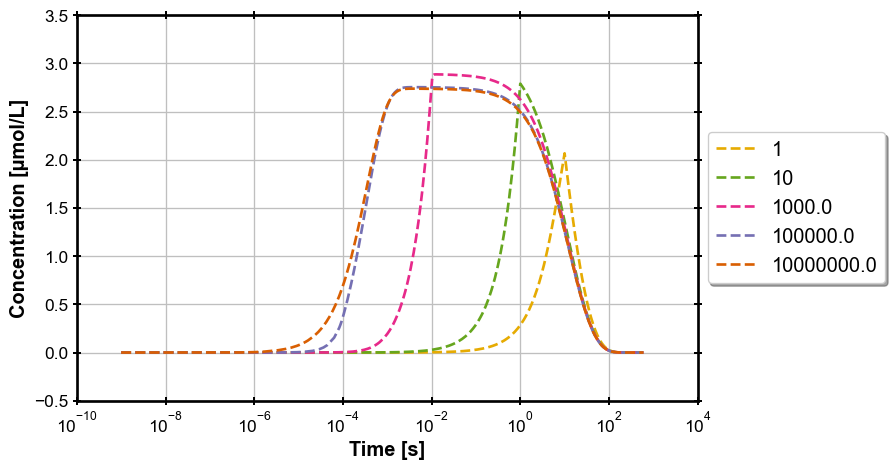

In [7]:
species = "ROO_r"
fig_man.set_brewer_map("Dark2", "qualitative", 6, reverse=True)
with fig_man.open(f"CONV Comparison of {species}") as (fig, ax):
    for value, df in sims.items():
        ax.plot(df.index, df[species], label=value, marker="")

    #ax.set_ylim(bottom=1e-6, top=2)
    #ax.set_xlim([1e-6, RIGHT_LIMIT])
    #ax.set_xlim([0, 100])
    ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    RPlot.set_legend_right(ax)
    #ax.legend(fancybox=True, framealpha=1)
    #ax.set_title("Biology related species")


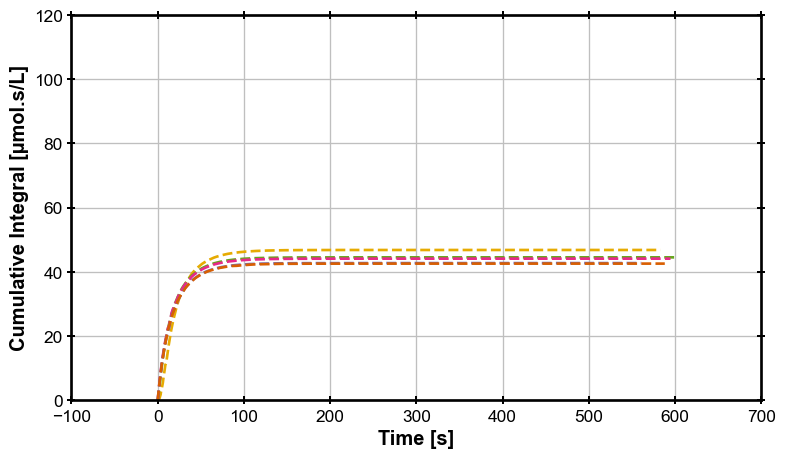

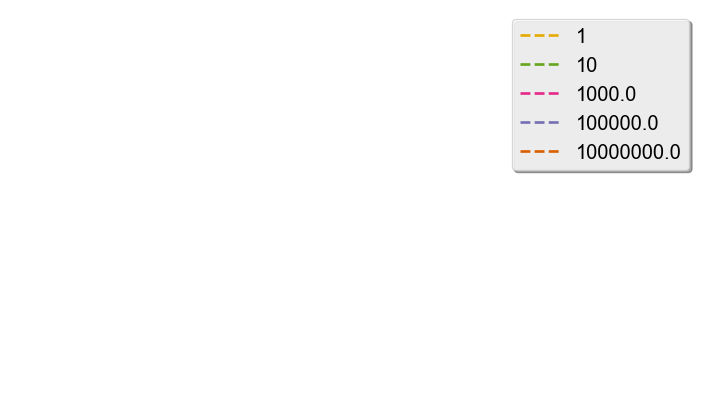

In [8]:
species = "ROO_r"
with fig_man.open(f"Conv - Cum Trapz{species}") as (fig, ax):
    for value, df in sims.items():
        l, = ax.plot(df.index[:-1],
                     cumulative_trapezoid(x=df.index.values,y=df["ROO_r"]),
                     label=value,
                     marker="")
    ax.set_ylim([0,120])
    #ax.set_xscale('log')
    #ax.set_yscale('log')
    #RPlot.set_legend_right(ax)
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Cumulative Integral [µmol.s/L]")
    
fig_l, ax_l = plt.subplots()
ax_l.axis("off")
legend = ax_l.legend(*ax.get_legend_handles_labels())#, bbox_to_anchor=(-0.0, -0.0))
fig_l.canvas.draw()
bbox  = legend.get_window_extent().transformed(fig_l.dpi_scale_trans.inverted())
#fig_l.set_size_inches(bbox.width, bbox.height)
#fig_l.tight_layout()
#fig.savefig(root/"Reactions_e_aq_10ppm_2000kGy.png")
#fig_l.savefig(root/"Reactions_e_aq_10ppm_legend_2000kGy.png", bbox_inches=bbox.expanded(1.02,1.04), transparent=True)

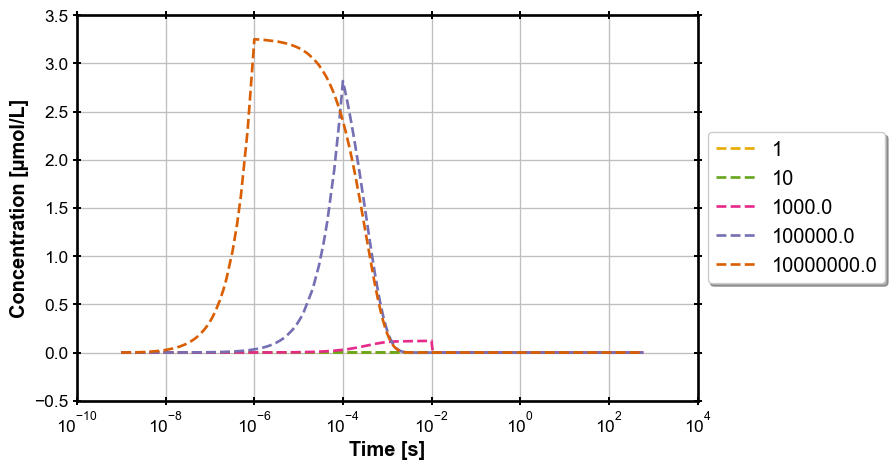

In [9]:
species = "R_r"
fig_man.set_brewer_map("Dark2", "qualitative", 6, reverse=True)
with fig_man.open(f"CONV Comparison of {species}") as (fig, ax):
    for value, df in sims.items():
        ax.plot(df.index, df[species], label=value, marker="")

    #ax.set_ylim(bottom=1e-6, top=2)
    #ax.set_xlim([1e-6, RIGHT_LIMIT])
    #ax.set_xlim([0, 100])
    ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    RPlot.set_legend_right(ax)
    #ax.legend(fancybox=True, framealpha=1)
    #ax.set_title("Biology related species")


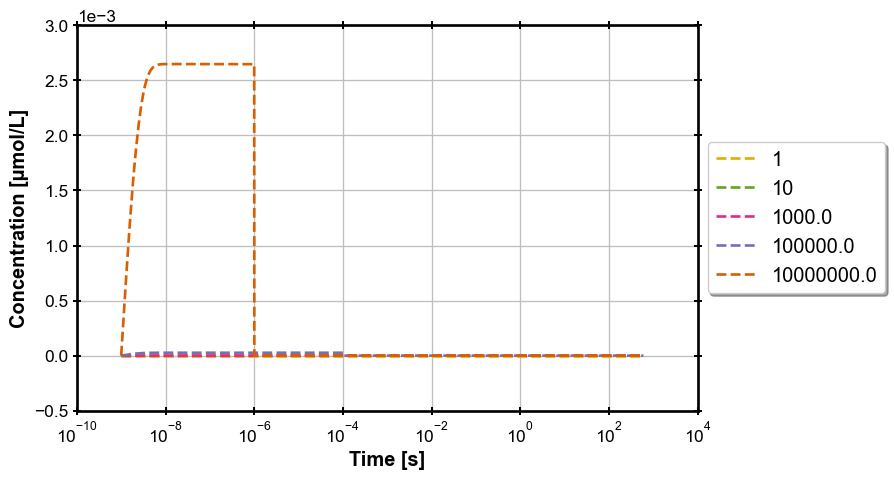

In [10]:
species = "OH_r"
fig_man.set_brewer_map("Dark2", "qualitative", 6, reverse=True)
with fig_man.open(f"CONV Comparison of {species}") as (fig, ax):
    for value, df in sims.items():
        ax.plot(df.index, df[species], label=value, marker="")

    #ax.set_ylim(bottom=1e-6, top=2)
    #ax.set_xlim([1e-6, RIGHT_LIMIT])
    #ax.set_xlim([0, 100])
    ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    RPlot.set_legend_right(ax)
    #ax.legend(fancybox=True, framealpha=1)
    #ax.set_title("Biology related species")


#### O2

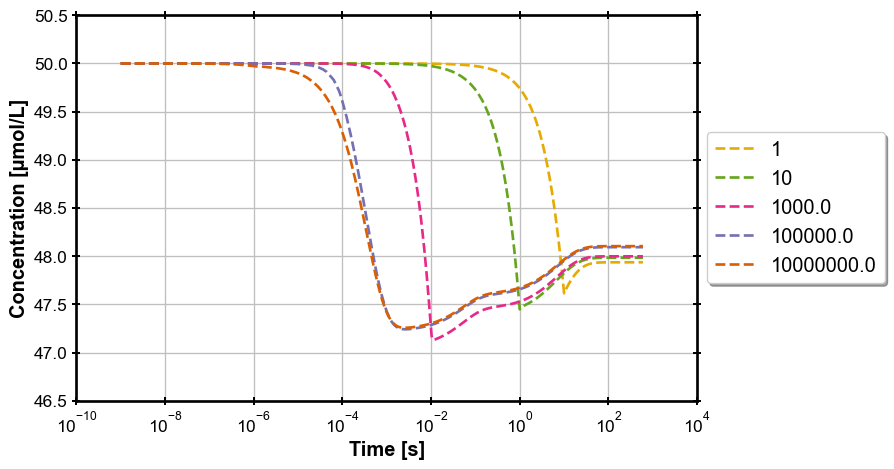

In [11]:
species = "O2"
fig_man.set_brewer_map("Dark2", "qualitative", 6, reverse=True)
with fig_man.open(f"CONV Comparison of {species}") as (fig, ax):
    for value, df in sims.items():
        ax.plot(df.index, df[species], label=value, marker="")

    #ax.set_ylim(bottom=1e-6, top=2)
    #ax.set_xlim([1e-6, RIGHT_LIMIT])
    #ax.set_xlim([0, 100])
    ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    RPlot.set_legend_right(ax)
    #ax.legend(fancybox=True, framealpha=1)
    #ax.set_title("Biology related species")


## Compare Chemical reaction rates

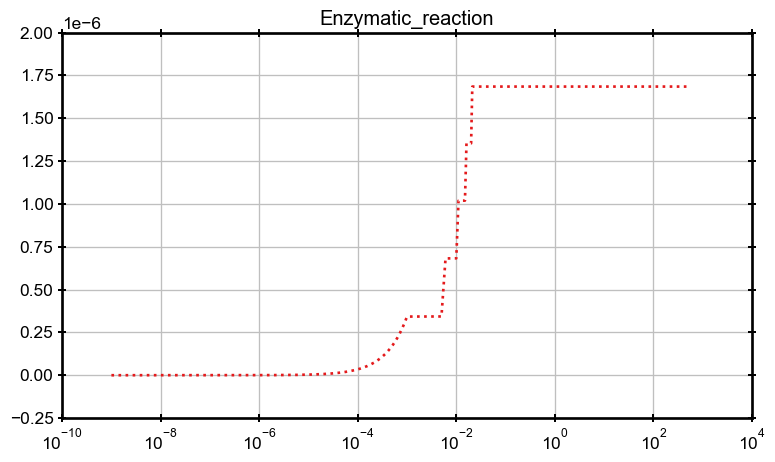

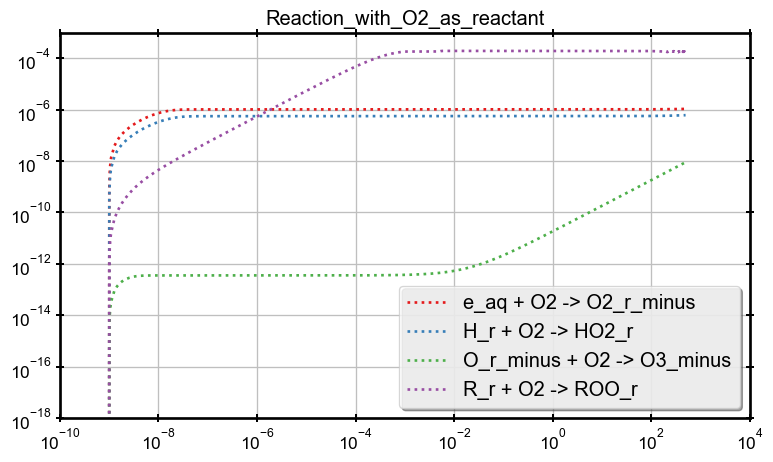

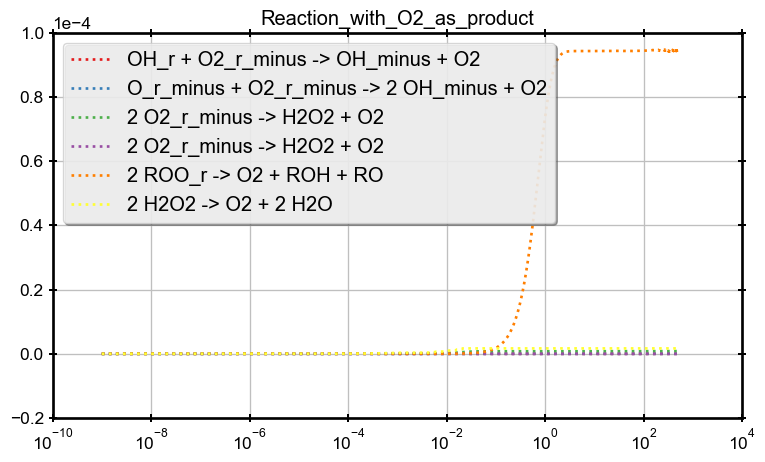

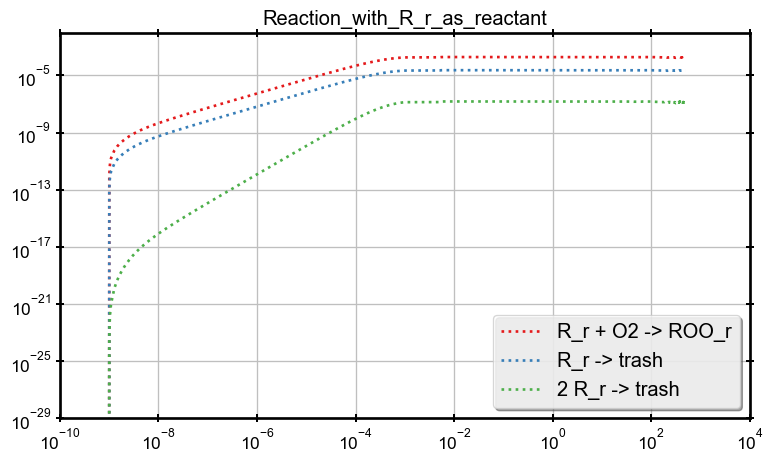

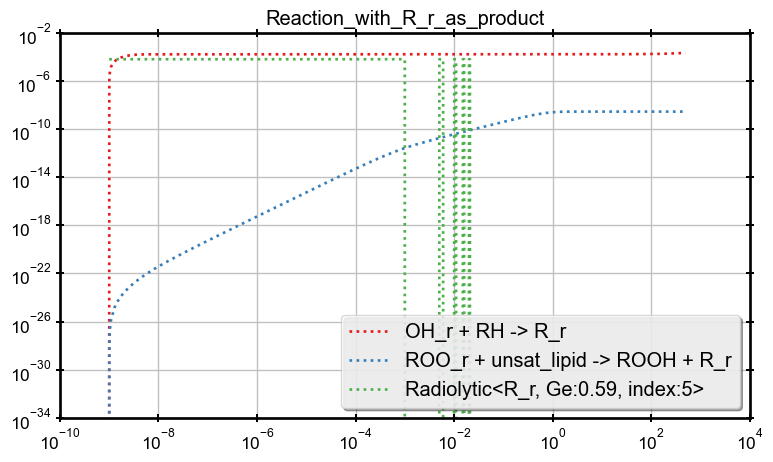

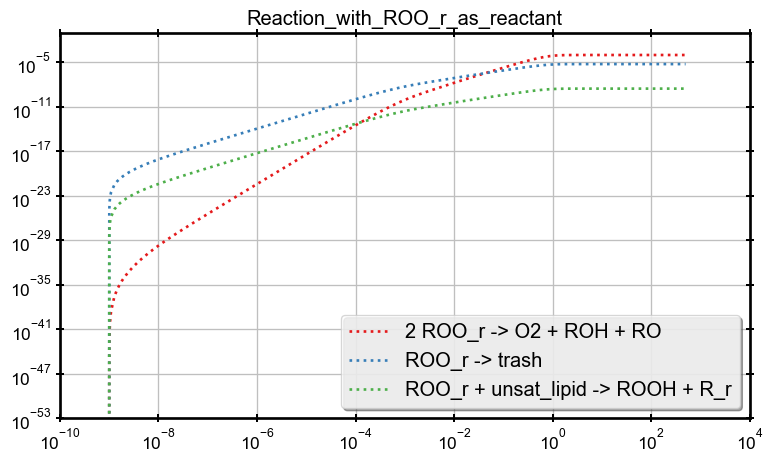

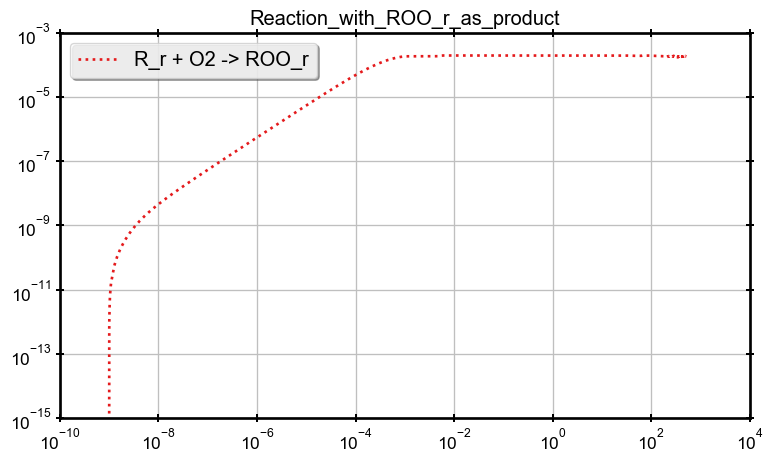

C:\Users\rtonneau\AppData\Local\Temp\ipykernel_18404\1964718746.py:60: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_yscale("log")


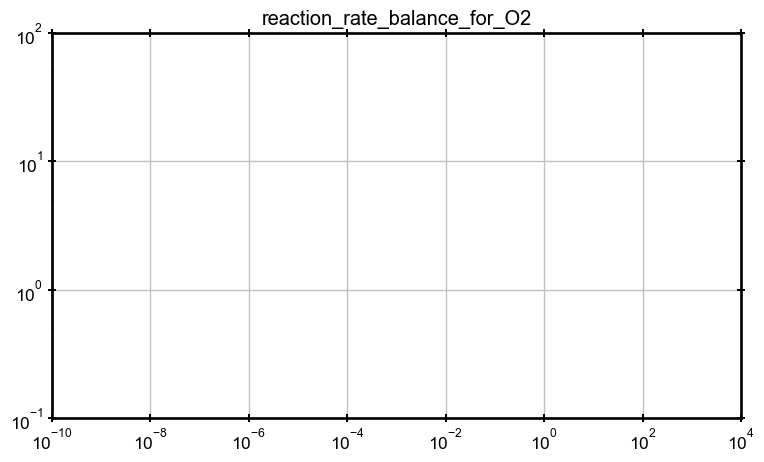

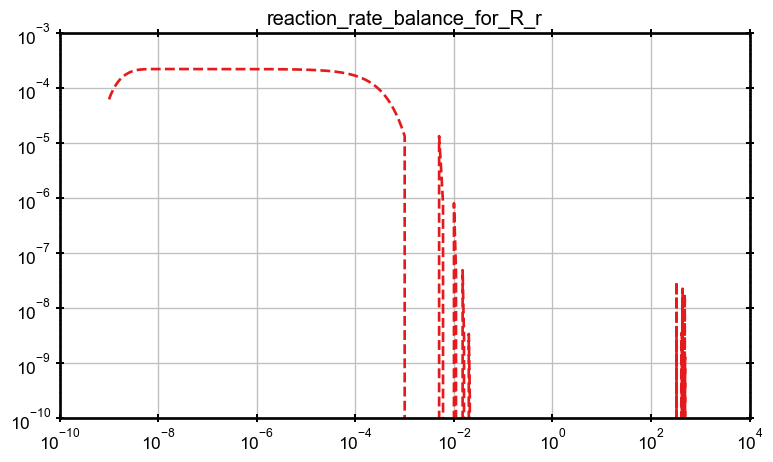

In [15]:
res = all_res[5e-3]
df_r = res.reconstruct_reactions()
df_b = res.species_balance_evolution()

fig_man.set_brewer_map("Set1", "qualitative", 6, reverse=False)

with fig_man.open(f"Enzymatic reaction") as (fig, ax):
    ax.semilogx(df_r.index, df_r["EZ_0"], label="fEZ_0", marker="", linestyle=":")
    ax.set_title(fig_man.last)

        
with fig_man.open(f"Reaction with O2 as reactant") as (fig, ax):
    for reaction in res.env.reactions_involving_reactant("O2"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
        ax.legend()
        ax.set_title(fig_man.last)
        ax.set_yscale("log")

with fig_man.open(f"Reaction with O2 as product") as (fig, ax):
    for reaction in res.env.reactions_involving_product("O2"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
        ax.legend()
        ax.set_title(fig_man.last)


with fig_man.open(f"Reaction with R_r as reactant") as (fig, ax):
    for reaction in res.env.reactions_involving_reactant("R_r"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
    ax.legend()
    ax.set_title(fig_man.last)
    ax.set_yscale("log")
    

with fig_man.open(f"Reaction with R_r as product") as (fig, ax):
    for reaction in res.env.reactions_involving_product("R_r"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
    ax.legend()
    ax.set_title(fig_man.last)
    ax.set_yscale("log")

with fig_man.open(f"Reaction with ROO_r as reactant") as (fig, ax):
    for reaction in res.env.reactions_involving_reactant("ROO_r"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
    ax.legend()
    ax.set_title(fig_man.last)
    ax.set_yscale("log")
    

with fig_man.open(f"Reaction with ROO_r as product") as (fig, ax):
    for reaction in res.env.reactions_involving_product("ROO_r"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
    ax.legend()
    ax.set_title(fig_man.last)
    ax.set_yscale("log")

    
with fig_man.open(f"reaction rate balance for O2") as (fig, ax):
    ax.semilogx(df_b.index, df_b["O2"], marker="")
    ax.set_title(fig_man.last)
    ax.set_yscale("log")

with fig_man.open(f"reaction rate balance for R_r") as (fig, ax):
    ax.semilogx(df_b.index, df_b["R_r"], marker="")
    ax.set_title(fig_man.last)
    ax.set_yscale("log")

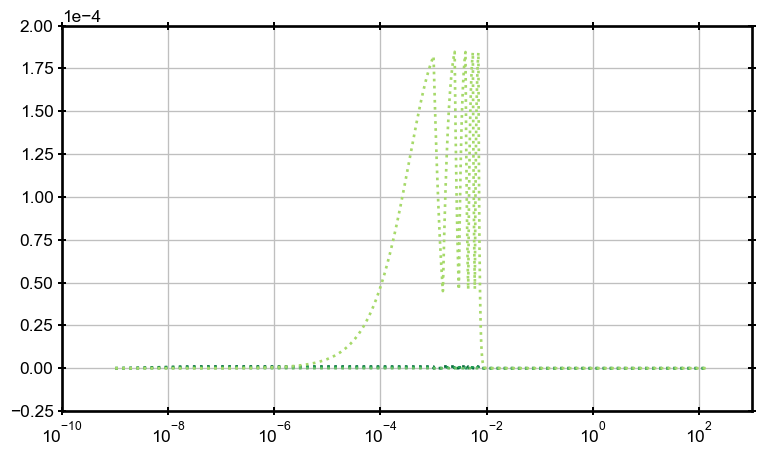

In [71]:
res = all_res[5e-3]
with fig_man.open(f"Reaction with R_r as product") as (fig, ax):
    df_r = all_res[1.5e-3].reconstruct_reactions()
    for reaction in res.env.reactions_involving_product("R_r"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")

## Compare Pulses

**Integrate values per pulse**

In [51]:
by_pulse = pd.DataFrame(columns=df.columns)
for pulse in range(int(PULSES_NUMBER)):
    by_pulse.loc[pulse, :] = res.integrate_species(start=pulse*uc.beam.timer.period, stop=(pulse+1)*uc.beam.timer.period)

NameError: name 'PULSES_NUMBER' is not defined

In [33]:
by_pulse

,OH_r,O_r_minus,H2O2,HO2_minus,HO2_r,O2_r_minus,e_aq,H_r,H2,O2,O2_minus_minus,O3_minus,Fe_plus_plus_plus,RH_r,R_r,ROO_r,ROH,RO,ROOH
0,0.0,0.0,0.000038,0.0,0.0,0.000002,0.0,0.0,0.000063,9.999233,0.0,0.0,0.0,0.000285,0.000001,0.000615,0.0,0.0,0.0
1,0.0,0.0,0.000044,0.0,0.0,0.000004,0.0,0.0,0.000127,9.999921,0.0,0.000039,0.0,0.00053,0.0,0.000683,0.0,0.0,0.0
2,0.0,0.0,0.000044,0.0,0.0,0.000006,0.0,0.0,0.00019,9.999363,0.0,0.000137,0.0,0.000775,0.0,0.000747,0.0,0.0,0.0
3,0.0,0.0,0.000045,0.0,0.0,0.000007,0.0,0.0,0.000253,9.999367,0.0,0.000272,0.0,0.001022,0.0,0.000829,0.0,0.0,0.0
4,0.0,0.0,0.000044,0.0,0.0,0.000009,0.0,0.0,0.000315,9.953993,0.0,0.000429,0.0,0.001263,0.0,0.000911,0.0,0.0,0.0


### ON time

NameError: name 'by_pulse' is not defined

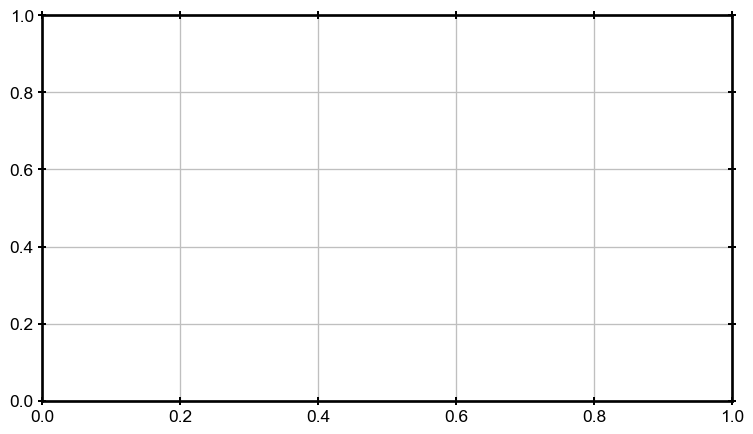

In [50]:
with fig_man.open(f"Pulse Integral") as (fig, ax):
    ax.plot(by_pulse.index+1, by_pulse["ROO_r"], label="ROO_r")
    ax.legend()

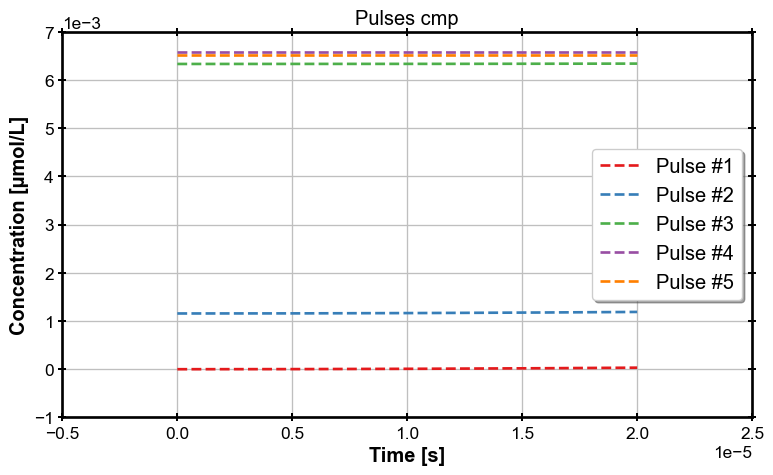

In [27]:
species = "ROO_r"
with fig_man.open(f"Pulses cmp") as (fig, ax):
    for pulse in range(int(PULSES_NUMBER)):
        start_pulse = pulse*uc.beam.timer.period
        mask = (df.index>=start_pulse) & (df.index < start_pulse+uc.beam.timer.on_time)
        ax.plot(df.index[mask]-start_pulse, df.loc[mask, species], label=f"Pulse #{pulse+1}", marker="")

    #ax.set_ylim(bottom=1e-6, top=100)
    #ax.set_xlim([1e-6,1])
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Pulses cmp")

### OFF Time

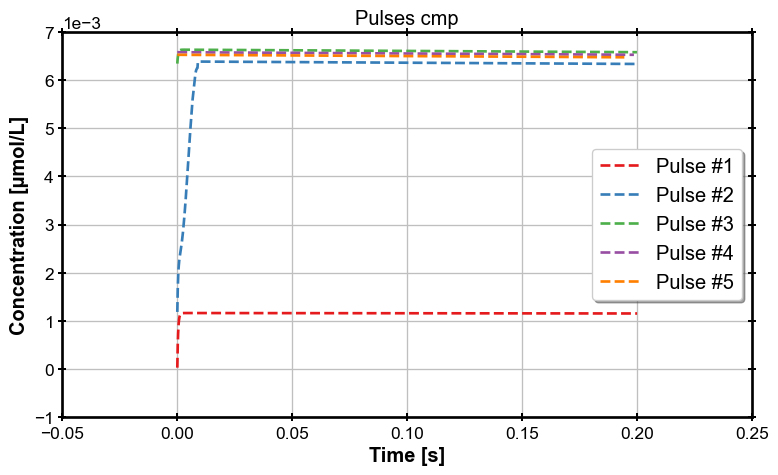

In [28]:
species = "ROO_r"
with fig_man.open(f"Pulses cmp") as (fig, ax):
    for pulse in range(int(PULSES_NUMBER)):
        start_pulse = pulse*uc.beam.timer.period + uc.beam.timer.on_time
        mask = (df.index>=start_pulse) & (df.index < (pulse+1)*uc.beam.timer.period)
        ax.plot(df.index[mask]-start_pulse, df.loc[mask, species], label=f"Pulse #{pulse+1}", marker="")

    #ax.set_ylim(bottom=1e-6, top=100)
    #ax.set_xlim([1e-6,0.12])
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Pulses cmp")